# Regressione logistica pesata: chi fa sport tra i giovani?
**Progetto Big Data for Official Statistics – notebook 02**

Fonte: ISTAT, *Aspetti della vita quotidiana* 2014-2024 (file ad uso pubblico), dataset costruito con `scripts/costruisci_avq.py`.

**Domande**
- **A.** Quali caratteristiche sono associate alla pratica sportiva tra gli 11 e i 24 anni, *a parità delle altre*? Il divario di genere e quello Nord-Sud restano dopo aver tenuto conto della famiglia?
- **B.** Nel notebook 01 i ragazzi con lezioni di recupero facevano *più* sport. È solo un effetto del reddito e del livello di istruzione della famiglia?

**Metodo**
- Regressione logistica stimata con i pesi campionari (pseudo-massima verosimiglianza). I pesi sono normalizzati a media 1: le stime non cambiano, ma i numeri restano leggibili.
- Errori standard **robusti "sandwich", raggruppati per famiglia**: tengono conto dei pesi e del fatto che i fratelli nella stessa famiglia si somigliano. Il file pubblico non ha strati e unità primarie, quindi non possiamo riprodurre esattamente il disegno ISTAT.
- I risultati sono presentati come **odds ratio (OR)** e come **probabilità predette standardizzate**: la quota di praticanti che avremmo se tutti avessero una certa caratteristica, lasciando invariato il resto. Gli intervalli delle probabilità vengono da 400 simulazioni dei coefficienti.
- Sono **associazioni**, non effetti causali.

Variabili di famiglia:
- `titolo_max_famiglia`: titolo di studio più alto tra i componenti di 25 anni e più;
- `risorse`: risorse economiche della famiglia negli ultimi 12 mesi (ottime o adeguate / scarse o insufficienti).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from scipy.special import expit
from scipy.stats import norm

# numpy 2.0 su macOS (libreria Accelerate) segnala per errore "divide by zero / overflow in matmul"
# anche su dati normali: i risultati sono corretti (verificato con np.einsum), quindi silenziamo solo quegli avvisi.
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

dati = pd.read_parquet(ROOT / "data" / "processed" / "avq_sport_2014_2024.parquet")

GIOVANI = ["11-13", "14-15", "16-17", "18-19", "20-24"]
g = dati[dati.eta_classe.isin(GIOVANI)].copy()
g["risorse"] = pd.Categorical(
    np.where(g.risorse_economiche.isin(["Ottime", "Adeguate"]), "Ottime o adeguate",
             np.where(g.risorse_economiche.notna(), "Scarse o insufficienti", None)),
    categories=["Ottime o adeguate", "Scarse o insufficienti"])
g["anno_f"] = g.anno.astype(str)
g["famiglia"] = pd.factorize(g.anno.astype(str) + "_" + g.id_famiglia.astype(str))[0]
for col in g.select_dtypes("category"):
    g[col] = g[col].cat.remove_unused_categories()
print(f"{len(g):,} giovani 11-24 anni")

65,331 giovani 11-24 anni


In [2]:
# Stile grafici (palette di riferimento, modalità chiara)
SUPERFICIE, TESTO, TESTO_2, GRIGLIA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLU, ARANCIO, ACQUA = "#2a78d6", "#eb6834", "#1baf7a"
COLORI_SESSO = {"Maschio": BLU, "Femmina": ARANCIO}
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": TESTO, "axes.labelcolor": TESTO_2, "xtick.color": TESTO_2, "ytick.color": TESTO_2,
    "axes.edgecolor": GRIGLIA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRIGLIA, "grid.linewidth": 0.8, "lines.linewidth": 2, "legend.frameon": False,
})

def fonte(ax, testo="Fonte: elaborazione su microdati ISTAT AVQ 2014-2024 (file ad uso pubblico)", y=-0.16):
    ax.annotate(testo, xy=(0, y), xycoords="axes fraction", fontsize=8, color=TESTO_2)

### Funzioni di stima

In [3]:
class LogitPesata:
    # Regressione logistica con pesi campionari ed errori standard sandwich raggruppati per famiglia.

    def __init__(self, formula, df, peso="peso", cluster="famiglia"):
        variabili = [c for c in df.columns if c in set(re.findall(r"\w+", formula))] + [peso, cluster]
        self.df = df.dropna(subset=variabili).copy()
        self.df["_w"] = self.df[peso] / self.df[peso].mean()
        self.modello = smf.glm(formula, self.df, family=sm.families.Binomial(),
                               var_weights=self.df["_w"]).fit()
        X, y = self.modello.model.exog, self.modello.model.endog
        w, p = self.df["_w"].to_numpy(), self.modello.fittedvalues.to_numpy()
        pane = np.linalg.inv((X * (w * p * (1 - p))[:, None]).T @ X)
        punteggi = pd.DataFrame(X * (w * (y - p))[:, None]).groupby(self.df[cluster].to_numpy()).sum()
        G = len(punteggi)
        V = pane @ (punteggi.T.to_numpy() @ punteggi.to_numpy()) @ pane * G / (G - 1)
        self.params = self.modello.params
        self.cov = pd.DataFrame(V, index=self.params.index, columns=self.params.index)
        self.se = np.sqrt(np.diag(self.cov))
        self.n, self.n_famiglie = len(self.df), G
        ll_nullo = smf.glm("_y ~ 1", self.df.assign(_y=y), family=sm.families.Binomial(),
                           var_weights=self.df["_w"]).fit().llf
        self.pseudo_r2 = 1 - self.modello.llf / ll_nullo

    def odds_ratio(self):
        z = self.params / self.se
        return pd.DataFrame({
            "OR": np.exp(self.params), "IC_basso": np.exp(self.params - 1.96 * self.se),
            "IC_alto": np.exp(self.params + 1.96 * self.se),
            "p_value": 2 * norm.sf(np.abs(z)),
        })

    def probabilita(self, **valori):
        # Probabilità predetta standardizzata: tutti con i valori indicati, il resto com'è.
        # Restituisce stima e IC 95% da 400 simulazioni dei coefficienti.
        d = self.df.copy()
        for k, v in valori.items():
            d[k] = pd.Categorical([v] * len(d), categories=self.df[k].cat.categories) \
                if isinstance(self.df[k].dtype, pd.CategoricalDtype) else v
        X = np.asarray(build_design_matrices([self.modello.model.data.design_info], d)[0])
        w = d["_w"].to_numpy() / d["_w"].sum()
        stima = w @ expit(X @ self.params.to_numpy())
        sim = np.random.default_rng(1).multivariate_normal(self.params, self.cov, 400)
        dist = w @ expit(X @ sim.T)
        return 100 * stima, 100 * np.percentile(dist, 2.5), 100 * np.percentile(dist, 97.5)

    def riepilogo(self):
        return f"n = {self.n:,} giovani, {self.n_famiglie:,} famiglie, pseudo-R² di McFadden = {self.pseudo_r2:.3f}"


def etichetta(termine):
    # 'sesso[T.Femmina]' -> ('sesso', 'Femmina')
    if "[T." in termine:
        var, livello = termine.split("[T.")
        return var.replace("C(", "").replace(")", ""), livello.rstrip("]")
    return termine, termine

## A. Chi fa sport tra gli 11 e i 24 anni?
Modello: `pratica_sport ~ sesso × età + ripartizione + titolo più alto in famiglia + risorse economiche + anno`

L'interazione **sesso × età** permette al divario tra ragazzi e ragazze di cambiare con l'età, come suggeriva il notebook 01.

In [4]:
g["y"] = g.pratica_sport.astype(float)
A = LogitPesata("y ~ sesso * eta_classe + ripartizione + titolo_max_famiglia + risorse + C(anno_f)", g)
print(A.riepilogo())
or_A = A.odds_ratio()
or_A.to_csv(RES / "modelloA_odds_ratio.csv")
or_A[~or_A.index.str.contains("anno_f")].round(3)

n = 62,188 giovani, 43,648 famiglie, pseudo-R² di McFadden = 0.076


,OR,IC_basso,IC_alto,p_value
Intercept,6.654,5.942,7.451,0.000
sesso[T.Femmina],0.557,0.510,0.610,0.000
eta_classe[T.14-15],0.872,0.789,0.964,0.008
eta_classe[T.16-17],0.815,0.738,0.901,0.000
eta_classe[T.18-19],0.655,0.593,0.724,0.000
eta_classe[T.20-24],0.566,0.521,0.614,0.000
ripartizione[T.Nord-est],1.042,0.973,1.117,0.242
ripartizione[T.Centro],0.995,0.927,1.068,0.899
ripartizione[T.Sud],0.581,0.546,0.618,0.000
ripartizione[T.Isole],0.615,0.568,0.665,0.000


### Odds ratio (senza gli effetti anno)
Un OR maggiore di 1 vuol dire più probabilità di fare sport rispetto alla categoria di riferimento; minore di 1, meno. Asse logaritmico.

Riferimenti: maschio, 11-13 anni, Nord-ovest, laurea in famiglia, risorse ottime o adeguate.

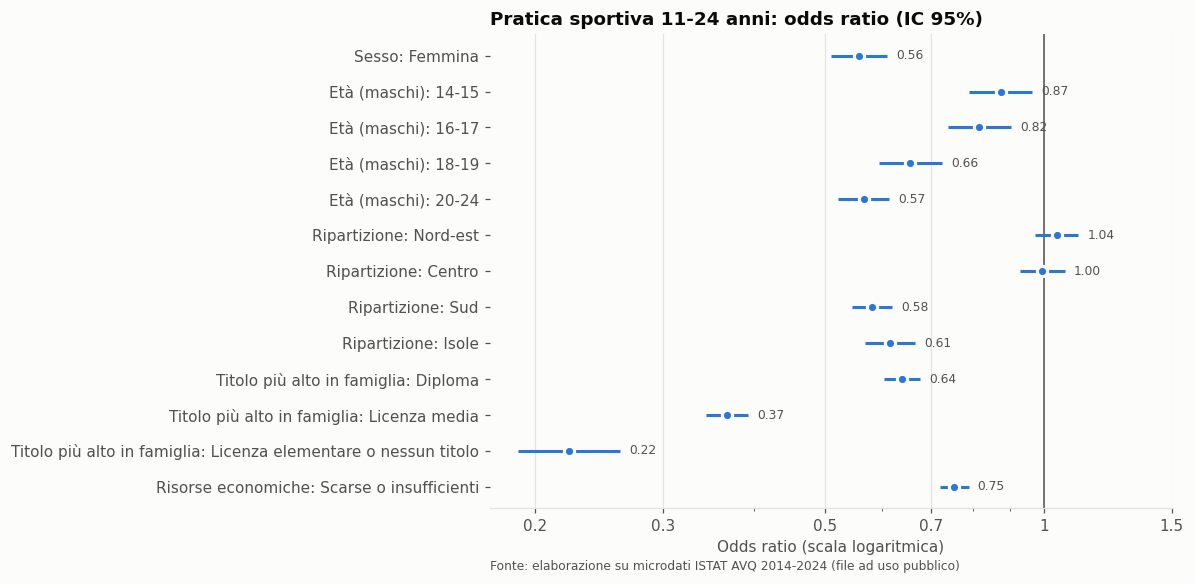

In [5]:
NOMI = {"sesso": "Sesso", "ripartizione": "Ripartizione", "titolo_max_famiglia": "Titolo più alto in famiglia",
        "risorse": "Risorse economiche", "eta_classe": "Età (maschi)"}
tab = or_A[~or_A.index.str.contains("anno_f|Intercept|:")].copy()
tab["gruppo"] = [NOMI[etichetta(i)[0]] for i in tab.index]
tab["livello"] = [etichetta(i)[1] for i in tab.index]
tab["ord"] = tab.gruppo.map({k: i for i, k in enumerate(["Sesso", "Età (maschi)", "Ripartizione",
                                                         "Titolo più alto in famiglia", "Risorse economiche"])})
tab = tab.sort_values(["ord"], kind="stable")

fig, ax = plt.subplots(figsize=(8, 5.6))
y = np.arange(len(tab))[::-1]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.axvline(1, color=TESTO_2, linewidth=1)
ax.hlines(y, tab.IC_basso, tab.IC_alto, color=BLU, linewidth=2)
ax.scatter(tab.OR, y, color=BLU, s=45, zorder=3, edgecolor=SUPERFICIE, linewidth=2)
for yi, (_, r) in zip(y, tab.iterrows()):
    ax.annotate(f"{r.OR:.2f}", (r.IC_alto, yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=TESTO_2)
ax.set_yticks(y, [f"{r.gruppo}: {r.livello}" for _, r in tab.iterrows()])
ax.set_xscale("log")
ax.set_xticks([0.2, 0.3, 0.5, 0.7, 1, 1.5], ["0.2", "0.3", "0.5", "0.7", "1", "1.5"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("Pratica sportiva 11-24 anni: odds ratio (IC 95%)")
ax.set_xlabel("Odds ratio (scala logaritmica)")
fonte(ax, y=-0.13)
fig.savefig(FIG / "09_modelloA_odds_ratio.png")
plt.show()

### Probabilità predette: il divario di genere per età
Quota di praticanti predetta per ogni combinazione di sesso ed età, *a parità di territorio, famiglia e anno*.

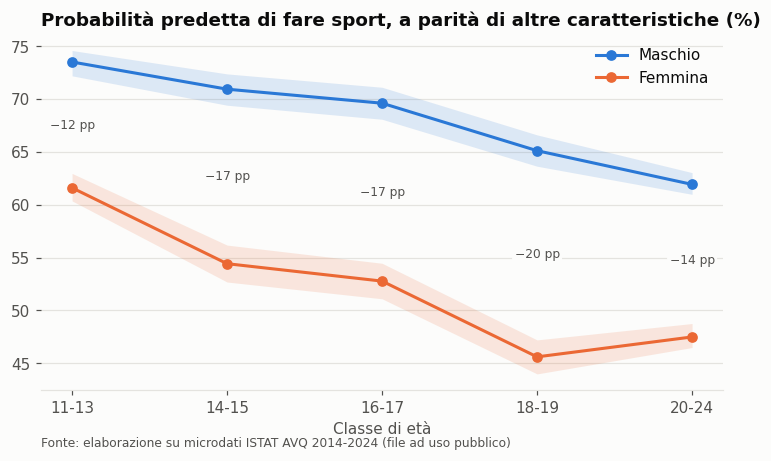

sesso,Femmina,Maschio,divario_pp
eta_classe,,,
11-13,61.6,73.5,11.9
14-15,54.4,70.9,16.5
16-17,52.8,69.6,16.8
18-19,45.6,65.1,19.5
20-24,47.5,61.9,14.4


In [6]:
righe = []
for sesso in ["Maschio", "Femmina"]:
    for eta in GIOVANI:
        p, lo, hi = A.probabilita(sesso=sesso, eta_classe=eta)
        righe.append({"sesso": sesso, "eta_classe": eta, "prob": p, "IC_basso": lo, "IC_alto": hi})
pred_eta = pd.DataFrame(righe)
pred_eta.to_csv(RES / "modelloA_prob_sesso_eta.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(GIOVANI))
for sesso, d in pred_eta.groupby("sesso", sort=False):
    c = COLORI_SESSO[sesso]
    ax.fill_between(x, d.IC_basso, d.IC_alto, color=c, alpha=0.15, linewidth=0)
    ax.plot(x, d.prob, color=c, marker="o", markersize=6, label=sesso)
divario = pred_eta.pivot(index="eta_classe", columns="sesso", values="prob").loc[GIOVANI]
for xi, (eta, r) in zip(x, divario.iterrows()):
    ax.annotate(f"−{r.Maschio - r.Femmina:.0f} pp", (xi, (r.Maschio + r.Femmina) / 2), ha="center",
                va="center", fontsize=8, color=TESTO_2,
                bbox=dict(boxstyle="round,pad=0.2", fc=SUPERFICIE, ec="none"))
ax.set_xticks(x, GIOVANI)
ax.set_xlabel("Classe di età")
ax.set_title("Probabilità predetta di fare sport, a parità di altre caratteristiche (%)")
ax.legend(loc="upper right")
fonte(ax)
fig.savefig(FIG / "10_modelloA_sesso_eta.png")
plt.show()
divario.assign(divario_pp=divario.Maschio - divario.Femmina).round(1)

### Probabilità predette: territorio e famiglia

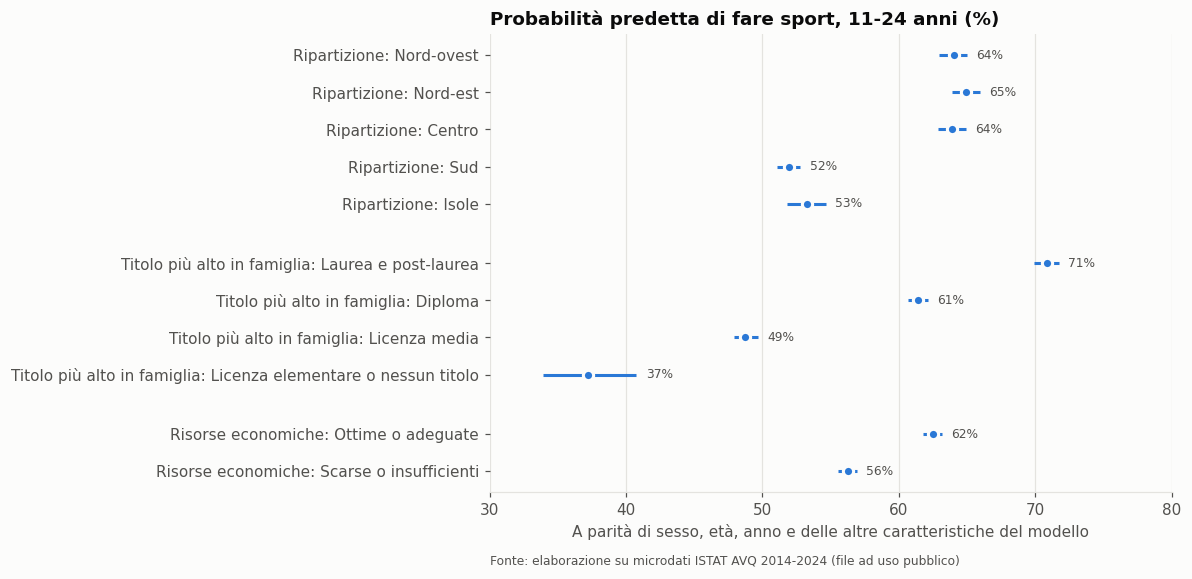

,gruppo,livello,prob,IC_basso,IC_alto
0,Ripartizione,Nord-ovest,64.0,63.0,65.0
1,Ripartizione,Nord-est,64.9,63.9,66.0
2,Ripartizione,Centro,63.9,62.9,64.9
3,Ripartizione,Sud,51.9,51.1,52.8
4,Ripartizione,Isole,53.2,51.8,54.7
5,Titolo più alto in famiglia,Laurea e post-laurea,70.8,69.9,71.7
6,Titolo più alto in famiglia,Diploma,61.4,60.7,62.1
7,Titolo più alto in famiglia,Licenza media,48.7,47.9,49.7
8,Titolo più alto in famiglia,Licenza elementare o nessun titolo,37.2,33.9,40.8
9,Risorse economiche,Ottime o adeguate,62.5,61.8,63.1


In [7]:
voci = (
    [("Ripartizione", r, {"ripartizione": r}) for r in A.df.ripartizione.cat.categories]
    + [("Titolo più alto in famiglia", t, {"titolo_max_famiglia": t}) for t in A.df.titolo_max_famiglia.cat.categories]
    + [("Risorse economiche", r, {"risorse": r}) for r in A.df.risorse.cat.categories]
)
pred_fam = pd.DataFrame([{"gruppo": gr, "livello": lv, **dict(zip(["prob", "IC_basso", "IC_alto"], A.probabilita(**kw)))}
                         for gr, lv, kw in voci])
pred_fam.to_csv(RES / "modelloA_prob_territorio_famiglia.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5.4))
yy = np.arange(len(pred_fam))[::-1] - pred_fam.gruppo.factorize()[0] * 0.6  # spazio tra i gruppi
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.hlines(yy, pred_fam.IC_basso, pred_fam.IC_alto, color=BLU, linewidth=2)
ax.scatter(pred_fam.prob, yy, color=BLU, s=45, zorder=3, edgecolor=SUPERFICIE, linewidth=2)
for yi, (_, r) in zip(yy, pred_fam.iterrows()):
    ax.annotate(f"{r.prob:.0f}%", (r.IC_alto, yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=TESTO_2)
ax.set_yticks(yy, [f"{r.gruppo}: {r.livello}" for _, r in pred_fam.iterrows()])
ax.set_xlim(30, 80)
ax.set_title("Probabilità predetta di fare sport, 11-24 anni (%)")
ax.set_xlabel("A parità di sesso, età, anno e delle altre caratteristiche del modello")
fonte(ax, y=-0.16)
fig.savefig(FIG / "11_modelloA_territorio_famiglia.png")
plt.show()
pred_fam.round(1)

## B. Lezioni di recupero e sport (11-19 anni)
Tre modelli annidati, stimati **sullo stesso campione** (anni con `lezioni_recupero` disponibile: 2014-2016 e 2019-2024):

1. ripetizioni + sesso + età + anno
2. \+ ripartizione
3. \+ titolo più alto in famiglia + risorse economiche

Se l'associazione dipendesse solo dal benessere della famiglia, l'OR delle ripetizioni dovrebbe avvicinarsi a 1 passando dal modello 1 al 3.

In [8]:
t = g[g.eta_classe.isin(["11-13", "14-15", "16-17", "18-19"]) & g.lezioni_recupero.notna()].copy()
t["ripetizioni"] = (t.lezioni_recupero != "No").astype(float)
t = t.dropna(subset=["y", "ripartizione", "titolo_max_famiglia", "risorse"])
for col in t.select_dtypes("category"):
    t[col] = t[col].cat.remove_unused_categories()

FORMULE = {
    "1. Base": "y ~ ripetizioni + sesso + eta_classe + C(anno_f)",
    "2. + Territorio": "y ~ ripetizioni + sesso + eta_classe + C(anno_f) + ripartizione",
    "3. + Famiglia": "y ~ ripetizioni + sesso + eta_classe + C(anno_f) + ripartizione + titolo_max_famiglia + risorse",
}
modelli_B = {nome: LogitPesata(f, t) for nome, f in FORMULE.items()}
or_B = pd.DataFrame({nome: m.odds_ratio().loc["ripetizioni"] for nome, m in modelli_B.items()}).T
or_B["n"] = [m.n for m in modelli_B.values()]
or_B["pseudo_R2"] = [m.pseudo_r2 for m in modelli_B.values()]
or_B.to_csv(RES / "modelloB_ripetizioni.csv")
or_B.round(3)

,OR,IC_basso,IC_alto,p_value,n,pseudo_R2
1. Base,1.704,1.531,1.896,0.0,32363,0.035
2. + Territorio,1.572,1.411,1.751,0.0,32363,0.051
3. + Famiglia,1.487,1.332,1.660,0.0,32363,0.084


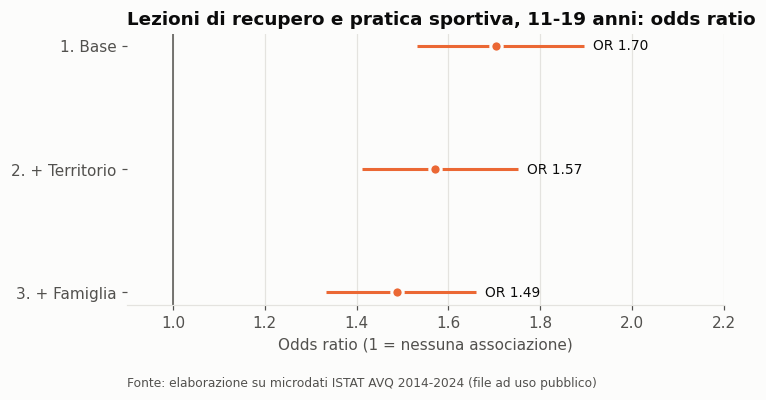

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
yy = np.arange(len(or_B))[::-1]
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.axvline(1, color=TESTO_2, linewidth=1)
ax.hlines(yy, or_B.IC_basso, or_B.IC_alto, color=ARANCIO, linewidth=2)
ax.scatter(or_B.OR, yy, color=ARANCIO, s=55, zorder=3, edgecolor=SUPERFICIE, linewidth=2)
for yi, (_, r) in zip(yy, or_B.iterrows()):
    ax.annotate(f"OR {r.OR:.2f}", (r.IC_alto, yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=TESTO)
ax.set_yticks(yy, or_B.index)
ax.set_xlim(0.9, 2.2)
ax.set_title("Lezioni di recupero e pratica sportiva, 11-19 anni: odds ratio")
ax.set_xlabel("Odds ratio (1 = nessuna associazione)")
fonte(ax, y=-0.3)
fig.savefig(FIG / "12_modelloB_ripetizioni.png")
plt.show()

In [10]:
# Lo stesso risultato in punti percentuali (modello 3)
m3 = modelli_B["3. + Famiglia"]
pp = pd.DataFrame([dict(zip(["prob", "IC_basso", "IC_alto"], m3.probabilita(ripetizioni=v)), ripetizioni=lab)
                   for v, lab in [(0.0, "Nessuna ripetizione"), (1.0, "Con ripetizioni")]]).set_index("ripetizioni")
pp.round(1)

,prob,IC_basso,IC_alto
ripetizioni,,,
Nessuna ripetizione,61.5,60.9,62.2
Con ripetizioni,69.5,67.3,71.5


## Lettura dei risultati
*(I numeri esatti sono nelle tabelle sopra e in `results/`.)*

**Modello A – giovani 11-24 anni** (62.188 giovani, 43.648 famiglie)
- **Genere:** a parità di territorio, famiglia e anno, le ragazze hanno una probabilità di fare sport più bassa di 12 punti a 11-13 anni, che sale a 20 punti a 18-19 anni (45,6% contro 65,1%). Il divario **non** si spiega con differenze di famiglia o territorio, e per le ragazze il calo con l'età è più ripido.
- **Territorio:** Sud e Isole restano circa 12 punti sotto il Centro-Nord (52-53% contro 64-65%) anche a parità di istruzione e risorse della famiglia. Il divario non è solo un effetto della composizione sociale.
- **Istruzione della famiglia:** è il fattore più forte. Si va dal 71% delle famiglie con almeno un laureato al 37% di quelle dove nessun adulto supera la licenza elementare.
- **Risorse economiche:** contano, ma meno: 62% con risorse ottime o adeguate contro 56% con risorse scarse o insufficienti.
- **Anni:** il 2021 (COVID) è l'unico anno nettamente sotto il 2014 (OR 0,76). Tra i giovani, a parità di caratteristiche, non c'è una crescita chiara dal 2014 al 2024.

**Modello B – ripetizioni** (32.363 ragazzi di 11-19 anni)
- Aggiungere territorio, istruzione e risorse della famiglia riduce l'odds ratio delle ripetizioni da 1,70 a 1,49, ma **non lo azzera**. In punti percentuali: 69,5% di praticanti con ripetizioni contro 61,5% senza, a parità del resto.
- Interpretazione possibile: le ripetizioni segnalano famiglie che investono di più nelle attività extrascolastiche dei figli, oltre a quanto misurano titolo di studio e risorse. Non c'è segno che le lezioni di recupero, come indicatore di difficoltà scolastica, tolgano tempo allo sport.

**Limiti**
- Dati trasversali: associazioni, non effetti causali.
- Gli errori standard non riproducono il disegno campionario completo (strati e unità primarie non sono nel file pubblico).
- Le risorse economiche sono una valutazione soggettiva della famiglia, non il reddito.
- `lezioni_recupero` è un proxy molto parziale del carico scolastico.